# Titanic Data Processing and Preprocessing

## Project Introduction

In this project, I will process and prepare the Titanic dataset using Python.

I will use Pandas, NumPy, and Scikit-learn to explore, clean, transform, and prepare the data for machine learning.

The goal is to understand each data processing step and prepare a clean dataset for a future machine learning model.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

## 1. Reading Dataset

In [2]:
df = pd.read_csv("C:\\Users\\Infotech\\OneDrive\\Desktop\\Data Proccessing\\train.csv")
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Understanding the Dataset

In this section, I will explore the dataset structure and understand the meaning of its columns.

Understanding the data is important before starting the cleaning and preprocessing stages.

In [3]:
df.shape

(891, 12)

In [4]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

## 3. Checking Data Types

In this section, I will check the data types of each column and identify missing values.

This helps me understand the dataset before cleaning it.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
df.isnull().sum().sum()

np.int64(866)

## 4. Handling Missing Values

Missing values are empty or unavailable values in a dataset.

In this section, I will identify the percentage of missing values in each column to decide how to handle them.

In [8]:
missing_values = df.isnull().sum()
missing_parcentage = (missing_values / len(df)) * 100

misiing_data = pd.DataFrame({"Missing Values" : missing_values , "Missing Percentage" : missing_parcentage})
misiing_data

,Missing Values,Missing Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


## 5. Handling Missing Values

In this section, I will handle missing values using different techniques.

- Median imputation for the Age column.
- Mode imputation for the Embarked column.

I will keep the Cabin column for further analysis before deciding whether to remove it.

In [9]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

## 6. Checking Duplicate Rows

Duplicate rows are records that appear more than once in a dataset.

In this section, I will check whether the dataset contains duplicate rows.

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.drop_duplicates()
df.shape

(891, 12)

In [12]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

## 7. Analyzing the Cabin Column

The Cabin column contains a large number of missing values.

Before removing this column, I will explore its available values to understand whether it contains useful information.

In [13]:
df["Cabin"].dropna().head(10)


1             C85
3            C123
6             E46
10             G6
11           C103
21            D56
23             A6
27    C23 C25 C27
31            B78
52            D33
Name: Cabin, dtype: str

## 8. Feature Extraction from Cabin

The Cabin column contains cabin identifiers.

I will extract the first letter from each cabin value to create a new feature called Deck.

This may help us identify patterns related to passenger survival.

In [14]:
df["Deck"] = df["Cabin"].str[0]
df[["Cabin" , "Deck"]].head(10)

,Cabin,Deck
0,NaN,NaN
1,C85,C
2,NaN,NaN
3,C123,C
4,NaN,NaN
5,NaN,NaN
6,E46,E
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


## 9. Analyzing Deck Distribution

In this section, I will explore the distribution of passengers across different cabin decks.

This will help me understand how many passengers belong to each deck.

In [15]:
df["Deck"].value_counts()

Deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

## 10. Handling Missing Deck Values

The Deck column contains missing values because many passengers do not have recorded cabin information.

I will replace these missing values with "Unknown" to preserve the passenger records.

In [16]:
df["Deck"] = df['Deck'].fillna("Unknown")
df["Deck"].value_counts()

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

## 11. Checking Data Types

Data type conversion is the process of changing a column from one data type to another when needed.

In this section, I will review the current data types after creating the new Deck feature.

In [17]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
Deck               str
dtype: object

## 12. Converting Columns to Categorical Data

Some numerical columns represent categories rather than continuous numerical values.

I will convert Pclass and Survived into categorical data types.

In [18]:
df["Pclass"] = df["Pclass"].astype("category")
df["Survived"] = df["Survived"].astype("category")
df[["Pclass" , "Survived"]].dtypes

Pclass      category
Survived    category
dtype: object

## 13. Checking Inconsistent Data

Inconsistent data occurs when the same information is represented in different formats.

In this section, I will inspect categorical columns to identify inconsistent values.

In [19]:
print("Sex Values:")
print(df["Sex"].unique())
print("\n Embarked Values:")
print(df["Embarked"].unique())
print("\nDeck Values:")
print(df["Deck"].unique())

Sex Values:
<StringArray>
['male', 'female']
Length: 2, dtype: str

 Embarked Values:
<StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str

Deck Values:
<StringArray>
['Unknown', 'C', 'E', 'G', 'D', 'A', 'B', 'F', 'T']
Length: 9, dtype: str


## 14. Detecting Outliers

Outliers are numerical values that are significantly different from most other values.

In this section, I will use the Interquartile Range (IQR) method to detect potential outliers in the Age column.

In [20]:
Q1 = df["Age"].quantile(0.25)
Q3 = df["Age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Age"] < lower_bound) | (df["Age"] > upper_bound)]
print("Q1:" , Q1)
print("Q3:" , Q3)
print("IQR:" , IQR)
print("Lower Bound:" , lower_bound)
print("Upper Bound:" , upper_bound)
print("Number of Outliers:" , len(outliers))

Q1: 22.0
Q3: 35.0
IQR: 13.0
Lower Bound: 2.5
Upper Bound: 54.5
Number of Outliers: 66


## 15. Visualizing Age Outliers

A boxplot helps visualize the distribution of numerical data and identify potential outliers.

I will use it to inspect the Age column.

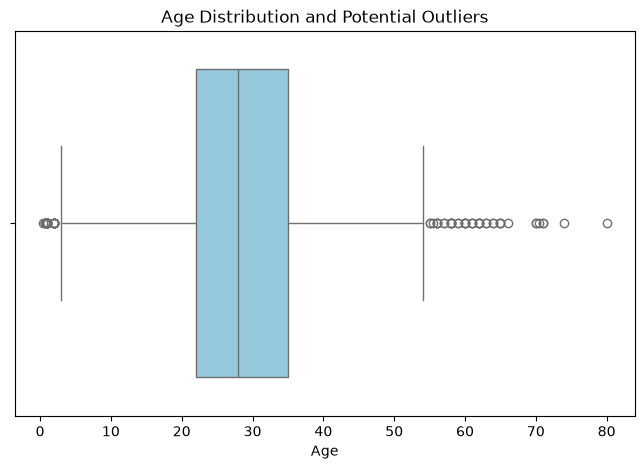

In [80]:
plt.figure(figsize=(8 , 5))
sns.boxplot(x = df["Age"] , color = "skyblue")
plt.title("Age Distribution and Potential Outliers")
plt.xlabel("Age")
plt.show()

## 16. Detecting Outliers in Fare

In this section, I will use the IQR method to detect potential outliers in the Fare column.

Ticket prices may vary significantly between passengers, so I will investigate their distribution before making any changes.

In [22]:
Q1_fare = df["Fare"].quantile(0.25)
Q3_fare = df["Fare"].quantile(0.75)
IQR_fare = Q3_fare - Q1_fare
lower_bound_fare = Q1_fare - 1.5 * IQR_fare
upper_bound_fare = Q3_fare + 1.5 * IQR_fare

outliers_fare = df[(df["Fare"] < lower_bound_fare) | (df["Fare"] > upper_bound_fare)]
print("Q1 (Fare):" , Q1_fare)
print("Q3 (Fare):" , Q3_fare)
print("IQR (Fare):" , IQR_fare)
print("Lower Bound (Fare):" , lower_bound_fare)
print("Upper Bound (Fare):" , upper_bound_fare)
print("Number of Outliers (Fare):" , len(outliers_fare))

Q1 (Fare): 7.9104
Q3 (Fare): 31.0
IQR (Fare): 23.0896
Lower Bound (Fare): -26.724
Upper Bound (Fare): 65.6344
Number of Outliers (Fare): 116


## 17. Visualizing Fare Outliers

In this section, I will use a boxplot to visualize the distribution of ticket fares and identify potential outliers.

Text(0.5, 0, 'Q3_fareplt.show()')

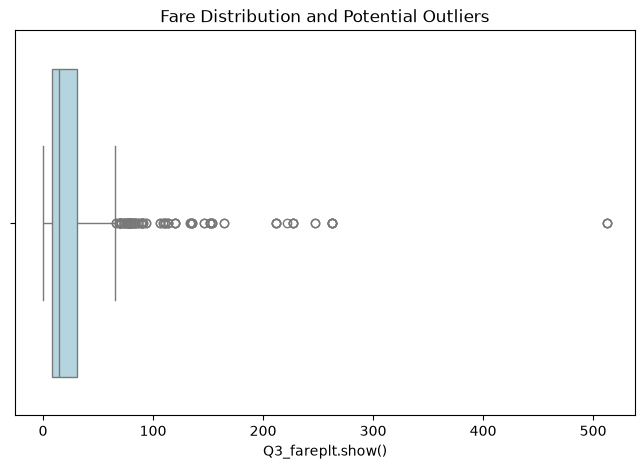

In [79]:
plt.figure(figsize=(8 , 5))
sns.boxplot(x=df["Fare"] , color = "lightblue")
plt.title("Fare Distribution and Potential Outliers")
plt.xlabel("Q3_fareplt.show()")

## 18. Feature Engineering - Family Information

Feature Engineering is the process of creating new features from existing data.

In this section, I will create two new features:

- FamilySize: The total number of family members traveling with the passenger, including the passenger.
- IsAlone: Indicates whether the passenger is traveling alone.

In [24]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0



## 19. Extracting Titles from Names

The Name column contains passenger names and titles.

In this section, I will extract passenger titles such as Mr, Mrs, Miss, and Master.

This creates a new feature that may provide useful information for machine learning.

In [26]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]*)\.")
df["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

## 20. Grouping Rare Titles

Some titles appear very rarely in the dataset.

In this section, I will group uncommon titles into a single category called "Rare".

This helps reduce the number of categories and simplifies the dataset.

In [29]:
rare_titles = ["Dr" , "Rev" , "Major" , "Mlle" , "Col" , "the Countess" , "Don" , "Mme" , "Ms" , "Lady" , "Sir" , "Capt" , "Jonkheer"]
df["Title"] = df["Title"].replace(rare_titles , "Rare")
df["Title"].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

## 21. Applying One-Hot Encoding

One-Hot Encoding converts categorical values into numerical columns.

In this section, I will encode the Sex column into separate binary columns.

In [30]:
sex_encoded = pd.get_dummies(df["Sex"] , prefix = "Sex" , dtype = int)
sex_encoded.head()

,Sex_female,Sex_male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1


## 22. Merging Encoded Columns

In this section, I will merge the newly created encoded columns with the original dataset.

This allows the dataset to contain both the original information and the encoded numerical features.

In [35]:
df = pd.concat([df , sex_encoded] , axis = 1)
df[["Sex" , "Sex_female" , "Sex_male"]].head()

,Sex,Sex_female,Sex_female,Sex_female,Sex_female,Sex_male,Sex_male,Sex_male,Sex_male
0,male,0,0,0,0,1,1,1,1
1,female,1,1,1,1,0,0,0,0
2,female,1,1,1,1,0,0,0,0
3,female,1,1,1,1,0,0,0,0
4,male,0,0,0,0,1,1,1,1


## 23. Encoding Multiple Categorical Features

In this section, I will apply One-Hot Encoding to the Embarked, Title, and Deck columns.

This will convert categorical values into numerical features that can be used by machine learning algorithms.

In [36]:
encoded_features = pd.get_dummies(df[["Embarked" , "Deck" , "Title"]] , dtype = int)
encoded_features.head()

,Embarked_C,Embarked_Q,Embarked_S,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0
1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0
2,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0
3,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0
4,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0


## 24. Merging Encoded Features

In this step, we merge the newly encoded categorical features
with the original Titanic dataset.

In [38]:
df = pd.concat([df , encoded_features] , axis = 1)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,0,0,0,0,1,0,0,1,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,0,0,0,0,0,0,0,0,1,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,0,0,0,0,1,0,1,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,0,0,0,0,0,0,0,0,1,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,0,0,0,0,1,0,0,1,0,0


## 25.  Checking Encoded Features

In this step, we check the dataset columns after applying One-Hot Encoding.

In [39]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked',
 'Deck',
 'FamilySize',
 'IsAlone',
 'Title',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Embarked_C',
 'Embarked_Q',
 'Embarked_S',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Deck_Unknown',
 'Title_Master',
 'Title_Miss',
 'Title_Mr',
 'Title_Mrs',
 'Title_Rare',
 'Embarked_C',
 'Embarked_Q',
 'Embarked_S',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Deck_Unknown',
 'Title_Master',
 'Title_Miss',
 'Title_Mr',
 'Title_Mrs',
 'Title_Rare']

## 26. Removing Original Categorical Columns

After One-Hot Encoding, we remove the original categorical columns
because their information is now represented by numerical columns.

In [41]:
df = df.drop(columns = ["Sex" , "Embarked" , "Deck" , "Title"])
df.head()

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,...,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,...,0,0,0,0,1,0,0,1,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,...,0,0,0,0,0,0,0,0,1,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,...,0,0,0,0,1,0,1,0,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,...,0,0,0,0,0,0,0,0,1,0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,...,0,0,0,0,1,0,0,1,0,0


In [42]:
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'FamilySize',
 'IsAlone',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Sex_female',
 'Sex_male',
 'Embarked_C',
 'Embarked_Q',
 'Embarked_S',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Deck_Unknown',
 'Title_Master',
 'Title_Miss',
 'Title_Mr',
 'Title_Mrs',
 'Title_Rare',
 'Embarked_C',
 'Embarked_Q',
 'Embarked_S',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Deck_Unknown',
 'Title_Master',
 'Title_Miss',
 'Title_Mr',
 'Title_Mrs',
 'Title_Rare']

## 27. Removing Duplicate Columns

In this step, we remove duplicated column names while keeping
the first occurrence of each column.

In [44]:
df = df.loc[: , ~ df.columns.duplicated()]
df.columns[df.columns.duplicated()]

Index([], dtype='str')

## 28. Removing Unnecessary Features

We remove columns that are no longer needed after feature extraction.

The removed columns are PassengerId, Name, Ticket, and Cabin.

In [45]:
df = df.drop(columns = ["PassengerId" , "Name" , "Ticket" , "Cabin"])
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_female,Sex_male,...,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,22.0,1,0,7.2500,2,0,0,1,...,0,0,0,0,1,0,0,1,0,0
1,1,1,38.0,1,0,71.2833,2,0,1,0,...,0,0,0,0,0,0,0,0,1,0
2,1,3,26.0,0,0,7.9250,1,1,1,0,...,0,0,0,0,1,0,1,0,0,0
3,1,1,35.0,1,0,53.1000,2,0,1,0,...,0,0,0,0,0,0,0,0,1,0
4,0,3,35.0,0,0,8.0500,1,1,0,1,...,0,0,0,0,1,0,0,1,0,0


## 29. Checking the Processed Dataset

In this step, we check the dataset dimensions after data cleaning,
feature engineering, and categorical encoding.

In [51]:
print("Dataset Shape:" , df.shape)
print("\n Dataset Information:" , df.info())

Dataset Shape: (891, 27)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 27 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Survived      891 non-null    category
 1   Pclass        891 non-null    category
 2   Age           891 non-null    float64 
 3   SibSp         891 non-null    int64   
 4   Parch         891 non-null    int64   
 5   Fare          891 non-null    float64 
 6   FamilySize    891 non-null    int64   
 7   IsAlone       891 non-null    int64   
 8   Sex_female    891 non-null    int64   
 9   Sex_male      891 non-null    int64   
 10  Embarked_C    891 non-null    int64   
 11  Embarked_Q    891 non-null    int64   
 12  Embarked_S    891 non-null    int64   
 13  Deck_A        891 non-null    int64   
 14  Deck_B        891 non-null    int64   
 15  Deck_C        891 non-null    int64   
 16  Deck_D        891 non-null    int64   
 17  Deck_E        891 non-null    int64   
 

## 30. Final Missing Values Check

We check whether any missing values remain in the processed dataset.

In [53]:
df.isnull().sum().sum()

np.int64(0)

## 31. Statistical Summary

In this step, we generate descriptive statistics for numerical features.

This helps us understand the distribution, average, minimum,
maximum, and spread of the data.

In [54]:
df.describe()

,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_female,Sex_male,Embarked_C,Embarked_Q,...,Deck_E,Deck_F,Deck_G,Deck_T,Deck_Unknown,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,...,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,29.361582,0.523008,0.381594,32.204208,1.904602,0.602694,0.352413,0.647587,0.188552,0.086420,...,0.035915,0.014590,0.004489,0.001122,0.771044,0.044893,0.204265,0.580247,0.140292,0.030303
std,13.019697,1.102743,0.806057,49.693429,1.613459,0.489615,0.477990,0.477990,0.391372,0.281141,...,0.186182,0.119973,0.066890,0.033501,0.420397,0.207186,0.403390,0.493796,0.347485,0.171516
min,0.420000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,22.000000,0.000000,0.000000,7.910400,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,28.000000,0.000000,0.000000,14.454200,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
75%,35.000000,1.000000,0.000000,31.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,80.000000,8.000000,6.000000,512.329200,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 32. Target Variable Distribution

In this step, we examine the distribution of the target variable (Survived).

This helps us understand how many passengers survived and how many did not.

In [55]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

## 33. Target Variable Percentage Distribution

We calculate the percentage of passengers who survived
and those who did not survive.

In [56]:
survival_percantage = df["Survived"].value_counts(normalize = True)*100
survival_percantage

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

## 34.  Survival Distribution Visualization

We use a count plot to visualize the number of passengers
who survived and those who did not survive.

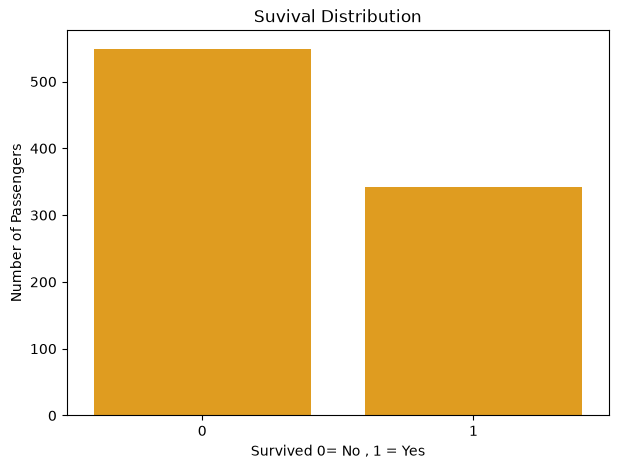

In [78]:
plt.figure(figsize = (7 , 5))
sns.countplot(data = df , x = "Survived" , color = "orange")
plt.title("Suvival Distribution")
plt.xlabel("Survived 0= No , 1 = Yes")
plt.ylabel("Number of Passengers")
plt.show()

## 35.  Survival Distribution Visualization

We use a count plot to visualize the number of passengers
who survived and those who did not survive.

In [62]:
gender_survivel = pd.DataFrame({
    "Famle": df.loc[df["Sex_female"] == 1,"Survived"].astype(int).mean(),
    "Male" : df.loc[df["Sex_male"] == 1,"Survived"].astype(int).mean(),
}
,index = ["Survival Rate"])
gender_survivel * 100

,Famle,Male
Survival Rate,74.203822,18.890815


## 36. Survival Rate by Gender Visualization

We visualize the survival rate of male and female passengers
using a bar plot.

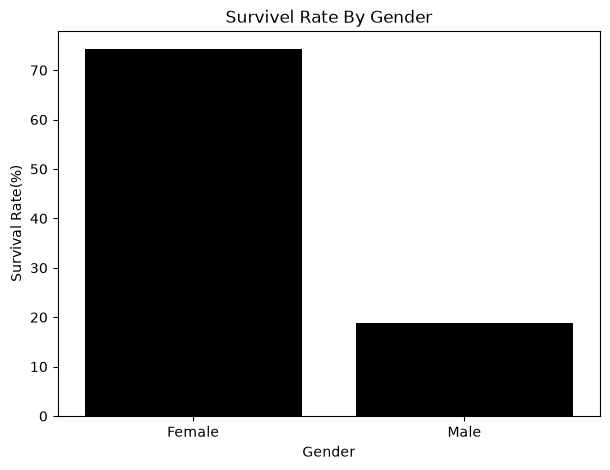

In [66]:
gender_survival_rate = df.groupby(df['Sex_female'].map({1:"Female",0:"Male"}),observed = True)["Survived"].apply(lambda x : x.astype(int).mean()*100)
plt.figure(figsize=(7 , 5))
sns.barplot(x = gender_survival_rate.index , y = gender_survival_rate.values , color = "Black")
plt.title("Survivel Rate By Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate(%)")
plt.show()

## 37. Survival Rate by Passenger Class

In this step, we calculate the survival rate for each passenger class.

We group passengers by Pclass and calculate the average survival rate.

In [68]:
class_survival = df.groupby("Pclass" , observed = True)["Survived"].apply(lambda x : x.astype(int).mean()* 100)
class_survival

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

## 38. Survival Rate by Passenger Class Visualization

We use a bar plot to compare survival rates across
the three passenger classes.

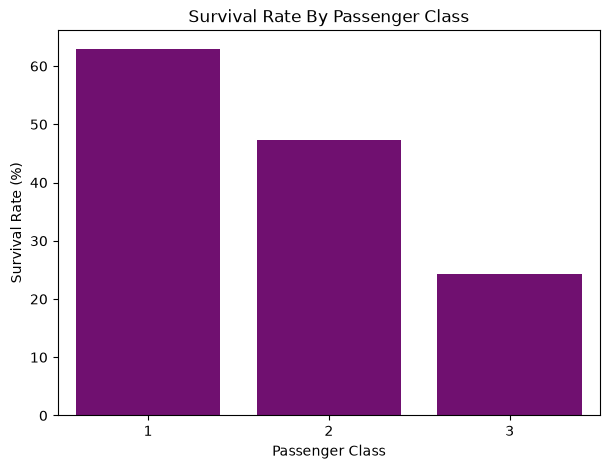

In [70]:
plt.figure(figsize = ( 7 , 5))
sns.barplot(x = class_survival.index.astype(str) , y = class_survival.values , color = "purple")
plt.title("Survival Rate By Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.show()

## 39. Survival Rate by Age Group

In this step, we divide passengers into three age groups:
Children, Adults, and Seniors.

Then, we calculate the survival rate for each group.

In [73]:
df["AgeGroup"] = pd.cut(df["Age"] , bins = [0 , 18 , 60 , float("inf")] , labels = ["Children" ,"Adults" , "Seniors"] , right = False)
df[["Age" , "AgeGroup"]].head(10)

,Age,AgeGroup
0,22.0,Adults
1,38.0,Adults
2,26.0,Adults
3,35.0,Adults
4,35.0,Adults
5,28.0,Adults
6,54.0,Adults
7,2.0,Children
8,27.0,Adults
9,14.0,Children


## 40. Survival Rate by Age Group

We calculate the survival rate for each age group
to understand how age is related to passenger survival.

In [74]:
age_survival = df.groupby("AgeGroup", observed = True)["Survived"].apply(lambda x : x.astype(int).mean()*100)
age_survival

AgeGroup
Children    53.982301
Adults      36.436170
Seniors     26.923077
Name: Survived, dtype: float64

## 41.  Survival Rate by Age Group Visualization

We use a bar plot to visualize the survival rate
across different age groups.

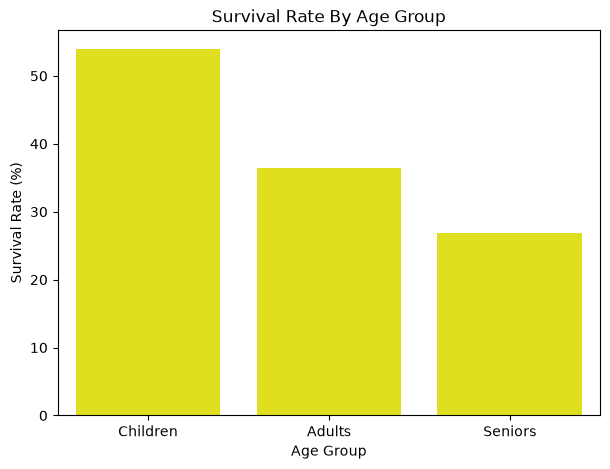

In [77]:
plt.figure(figsize = (7 , 5))
sns.barplot(x = age_survival.index , y = age_survival.values , color = "yellow")
plt.title("Survival Rate By Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.show()

## 42. Survival Rate by Family Size

In this step, we divide passengers into three groups
based on their family size.

- Alone: 1 passenger
- Small Family: 2 to 4 passengers
- Large Family: 5 or more passengers

In [85]:
df["FamilyGroup"] = "Large Family"

df.loc[df["FamilySize"].between(2, 4), "FamilyGroup"] = "Small Family"

df.loc[df["FamilySize"] == 1, "FamilyGroup"] = "Alone"

df[["FamilySize", "FamilyGroup"]].head(10)

,FamilySize,FamilyGroup
0,2,Small Family
1,2,Small Family
2,1,Alone
3,2,Small Family
4,1,Alone
5,1,Alone
6,1,Alone
7,5,Large Family
8,3,Small Family
9,2,Small Family


## 43. Survival Rate by Family Group

In this step, we calculate the survival rate for passengers
traveling alone, with small families, and with large families.

We compare the survival rates across these three groups.

In [86]:
family_survival = df.groupby("FamilyGroup", observed = True)["Survived"].apply(lambda x : x.astype(int).mean()*100)
family_survival

FamilyGroup
Alone           30.353818
Large Family    16.129032
Small Family    57.876712
Name: Survived, dtype: float64

## 44. Survival Rate by Family Group Visualization

We use a bar plot to compare the survival rates
of passengers across different family groups.

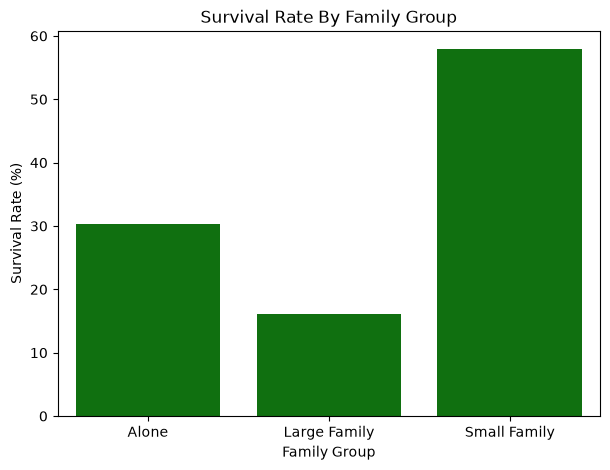

In [87]:
plt.figure(figsize = ( 7 , 5))
sns.barplot(x = family_survival.index , y = family_survival.values , color = "green") 
plt.title("Survival Rate By Family Group")
plt.xlabel("Family Group")
plt.ylabel("Survival Rate (%)")
plt.show()

## 45. Survival Rate by Fare Group

In this step, we divide passengers into three groups
based on their ticket fares.

- Low Fare: Less than 10
- Medium Fare: From 10 to less than 30
- High Fare: 30 or more

In [89]:
df["FareGroup"] = pd.cut(df["Fare"] , bins = [-1 , 10 , 30 , float("inf")] , labels = ["duplicates=Low Fare" , "Medium Fare" , "High Fare"] , right = False)
df[["Fare" , "FareGroup"]].head(10)

,Fare,FareGroup
0,7.2500,duplicates=Low Fare
1,71.2833,High Fare
2,7.9250,duplicates=Low Fare
3,53.1000,High Fare
4,8.0500,duplicates=Low Fare
5,8.4583,duplicates=Low Fare
6,51.8625,High Fare
7,21.0750,Medium Fare
8,11.1333,Medium Fare
9,30.0708,High Fare


In [92]:
df["FareGroup"].value_counts()

FareGroup
duplicates=Low Fare    336
Medium Fare            315
High Fare              240
Name: count, dtype: int64

In [94]:
print(df["FareGroup"].cat.categories)

Index(['duplicates=Low Fare', 'Medium Fare', 'High Fare'], dtype='str')


## 46. Survival Rate by Fare Group

In this step, we calculate the survival rate for each fare group.

We compare passengers who paid low, medium, and high ticket fares.

In [95]:
fare_survival = df.groupby(df["FareGroup"], observed = True)["Survived"].apply(lambda x : x.astype(int).mean()*100)
fare_survival

FareGroup
duplicates=Low Fare    19.940476
Medium Fare            42.539683
High Fare              58.750000
Name: Survived, dtype: float64

## 47. Survival Rate by Fare Group Visualization

We use a bar plot to compare survival rates
across different ticket fare groups.

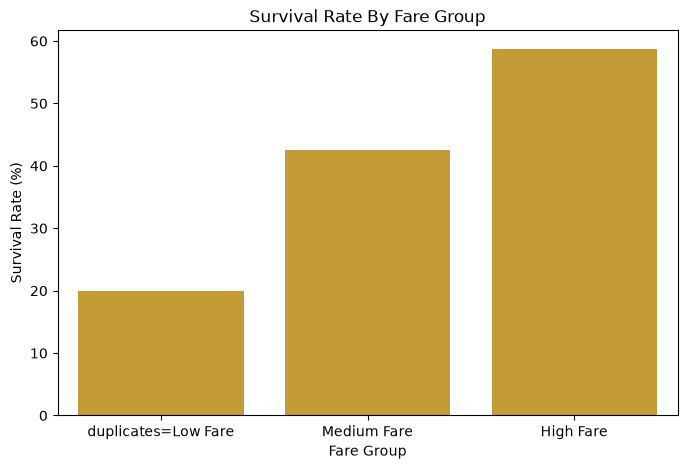

In [99]:
plt.figure(figsize = (8 , 5))
sns.barplot(x = fare_survival.index , y = fare_survival.values , color = "goldenrod")
plt.title("Survival Rate By Fare Group")
plt.xlabel("Fare Group")
plt.ylabel("Survival Rate (%)")
plt.show()

## 48. Final Feature Review

In this step, we review all the features created during
data cleaning, feature engineering, and categorical encoding.

We identify the input features and the target variable.

In [100]:
df.columns.tolist()

['Survived',
 'Pclass',
 'Age',
 'SibSp',
 'Parch',
 'Fare',
 'FamilySize',
 'IsAlone',
 'Sex_female',
 'Sex_male',
 'Embarked_C',
 'Embarked_Q',
 'Embarked_S',
 'Deck_A',
 'Deck_B',
 'Deck_C',
 'Deck_D',
 'Deck_E',
 'Deck_F',
 'Deck_G',
 'Deck_T',
 'Deck_Unknown',
 'Title_Master',
 'Title_Miss',
 'Title_Mr',
 'Title_Mrs',
 'Title_Rare',
 'AgeGroup',
 'FamilyGroup',
 'FareGroup']

## 49. Final Data Quality Check

In this section, we perform a final check to make sure
the processed dataset is clean and ready for analysis.

We check for:
- Missing values
- Duplicate rows
- Dataset dimensions

In [101]:
print("Missing Values:", df.isnull().sum().sum())
print("\nDuplicates Rows:", df.duplicated().sum())
print("\nDataset Shape:", df.shape)

Missing Values: 0

Duplicates Rows: 105

Dataset Shape: (891, 30)


## 50. Saving the Processed Dataset

After completing data processing and exploratory analysis,
we save the cleaned dataset as a CSV file.

This allows us to reuse the processed data in future
machine learning projects.

In [102]:
df.to_csv("Titanic_Processed.csv", index=False)

## 51. Separating Features and Target

In this step, we separate the dataset into two parts:

- Features (X): Input variables used by the model.
- Target (y): The output we want the model to predict.

Our target variable is Survived.

In [103]:
x = df.drop(columns = ["Survived" , "AgeGroup" , "FamilyGroup" , "FareGroup"])
y = df["Survived"].astype(int)
print("Features Shape:", x.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 26)
Target Shape: (891,)


## 52. Checking Feature Data Types

We inspect the data types of our input features
to identify numerical and categorical columns.

This helps us decide which preprocessing steps
are needed before model training.

In [107]:
print("Feature Data Types:")
print(x.dtypes)

print("\nCategorical Columns:")
print(x.select_dtypes(include=["category", "object"]).columns.tolist())

print("\nNumerical Columns:")
print(x.select_dtypes(include=["number"]).columns.tolist())

Feature Data Types:
Pclass          category
Age              float64
SibSp              int64
Parch              int64
Fare             float64
FamilySize         int64
IsAlone            int64
Sex_female         int64
Sex_male           int64
Embarked_C         int64
Embarked_Q         int64
Embarked_S         int64
Deck_A             int64
Deck_B             int64
Deck_C             int64
Deck_D             int64
Deck_E             int64
Deck_F             int64
Deck_G             int64
Deck_T             int64
Deck_Unknown       int64
Title_Master       int64
Title_Miss         int64
Title_Mr           int64
Title_Mrs          int64
Title_Rare         int64
dtype: object

Categorical Columns:
['Pclass']

Numerical Columns:
['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Deck_A', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_T', 'Deck_Unknown', 'Title_Master', 'Title_Miss', 'Title_Mr'

## 53. Converting Passenger Class to Numeric

The Pclass column represents passenger ticket classes.

Since the classes are already represented by numbers (1, 2, 3),
we convert the column from categorical to integer data type.

In [108]:
x["Pclass"] = x["Pclass"].astype(int)
print(x["Pclass"].dtype)
print(x["Pclass"].unique())

int64
[3 1 2]


## 54. Splitting the Dataset

We split the dataset into training and testing sets.

- 80% of the data is used for training.
- 20% of the data is used for testing.

We use stratify to maintain the same target class
distribution in both sets.

In [109]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42 , stratify=y)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)  
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (712, 26)
x_test: (179, 26)
y_train: (712,)
y_test: (179,)


## 55. Checking Target Distribution

We compare the survival distribution in the training
and testing datasets.

This helps us verify that both datasets maintain
approximately the same target class proportions.

In [110]:
print("Original Target Distrebution:")
print(y.value_counts(normalize=True) * 100)
print("\ntraining Target Distrebution:")
print(y_train.value_counts(normalize=True) * 100)
print("\nTesting Target Distrebution:")
print(y_test.value_counts(normalize=True) * 100)

Original Target Distrebution:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

training Target Distrebution:
Survived
0    61.657303
1    38.342697
Name: proportion, dtype: float64

Testing Target Distrebution:
Survived
0    61.452514
1    38.547486
Name: proportion, dtype: float64


## 56. Logistic Regression Model

Logistic Regression is a classification algorithm.

In this project, we use it to predict whether
a passenger survived or not.

The model learns patterns from the training data
and predicts survival outcomes.

In [111]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=(1000))

## 57. Training the Model

We train the Logistic Regression model using
the training features and their corresponding labels.

In [112]:
logistic_model.fit(x_train , y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## 58. Making Predictions

After training the Logistic Regression model,
we use it to predict survival outcomes
for the testing dataset.

The predictions are compared with the actual
survival values to evaluate model performance.

In [113]:
y_pred = logistic_model.predict(x_test)
print("Actual Values:")
print(y_test.head(10).tolist())
print("\nPredict Values:")
print(y_pred[:10])

Actual Values:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

Predict Values:
[0 0 0 0 1 1 1 0 0 0]


## 59. Model Evaluation - Accuracy

Accuracy measures the percentage of correct predictions
made by the model on the testing dataset.

It helps us understand the overall prediction performance.

In [116]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test , y_pred)
print("Model accuracy:",  accuracy * 100, "%")

Model accuracy: 84.35754189944134 %


## 60. Confusion Matrix

A Confusion Matrix evaluates classification performance
by comparing actual values with predicted values.

It shows:
- True Positives
- True Negatives
- False Positives
- False Negatives

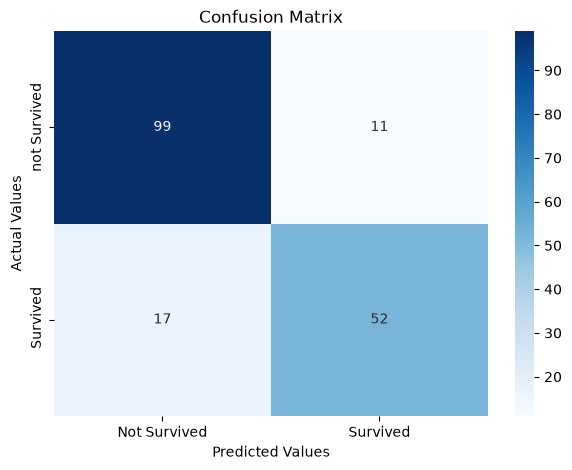

In [120]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test , y_pred)
plt.figure(figsize = ( 7 , 5))
sns.heatmap(cm , annot = True , fmt = "d" , cmap = "Blues" , xticklabels=["Not Survived" , "Survived"] , yticklabels=["not Survived" , " Survived"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

## 61. Precision and Recall

Precision measures how many positive predictions
were actually correct.

Recall measures how many actual positive cases
were correctly identified by the model.

In this project, the positive class represents
passengers who survived.

In [121]:
from sklearn.metrics import precision_score,recall_score

precision = precision_score(y_test , y_pred)
recall = recall_score(y_test , y_pred)
print("precision:",precision*100,"%")
print("recall:" , recall*100 , "%")

precision: 82.53968253968253 %
recall: 75.36231884057972 %


## 62. F1-Score

F1-Score combines Precision and Recall
into a single evaluation metric.

It uses the harmonic mean of both metrics.

A higher F1-Score indicates a better balance
between Precision and Recall.

In [122]:
from sklearn.metrics import f1_score
f = f1_score(y_test , y_pred)
print("f1_score:" , f * 100 , "%")

f1_score: 78.78787878787878 %


## 63. Classification Report

The Classification Report provides a detailed
evaluation of the classification model.

It includes:
- Precision
- Recall
- F1-Score
- Support

These metrics are calculated separately
for each target class.

In [123]:
from sklearn.metrics import classification_report
report = classification_report(y_test , y_pred , target_names=["Not Survived" , "Survived"])
print(report)

              precision    recall  f1-score   support

Not Survived       0.85      0.90      0.88       110
    Survived       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



## 64. Logistic Regression - Model Evaluation

The Logistic Regression model achieved an accuracy of 84.36%
on the testing dataset.

The model achieved:
- Precision: 82.54%
- Recall: 75.36%
- F1-Score: 78.79%

The classification report shows that the model performs
better at identifying passengers who did not survive.

The recall for the Survived class is 75%, which means
the model successfully identified approximately 75%
of the actual survivors.

Overall, Logistic Regression provides a good baseline
for our Titanic classification project, but there is
still room for improvement.